# C4: Deployment & Model Cards

**FIT1061 Introduction to Artificial Intelligence — Credit Task 4**

In 2018, a self-driving car struck and killed a pedestrian in Arizona — the safety operator was not watching the road. In 2023, a lawyer was sanctioned for submitting a legal brief citing court cases that a chatbot had fabricated. And training a single frontier model can consume an estimated 50+ GWh of energy — enough to power thousands of homes for a year.

Each example illustrates a different failure mode: **safety** (the system harms someone physically), **reliability** (the system produces convincing falsehoods), and **sustainability** (the system costs more than we realise). You've spent the semester building AI systems that work in the notebook. This task asks: what happens when they enter the real world?

You'll simulate **distribution shift** on a classifier you've already built, write a **Model Card** documenting its capabilities and limitations, and estimate the **carbon footprint** of a training run. These are the skills that separate someone who can build a model from someone who can responsibly deploy one.

> **Prerequisite:** C3 (Ready for Feedback). You'll use the same Naive Bayes classifier architecture from W7.

> **Credit level:** Less scaffolding than PASS tasks. We provide the classifier, datasets, and plotting code; you implement the analysis functions and write the Model Card.

---

## Setup

In [1]:
import numpy as np

from c4_helpers import (
    classifier, TRAIN_DATA,
    TEST_SAME, TEST_SHIFTED,
    CARBON_CONSTANTS, COMPARISON_VALUES,
    TRAINING_COST_HISTORY,
    WEAK_MODEL_CARD,
    compute_metrics,
    plot_shift_comparison, plot_carbon_scaling, plot_efficiency_table,
)

print("Setup OK.")
print(f"Training data: {len(TRAIN_DATA)} messages")
print(f"Test (same distribution): {len(TEST_SAME)} messages")
print(f"Test (shifted distribution): {len(TEST_SHIFTED)} messages")
print(f"Classifier vocab size: {len(classifier.vocab)}")

Setup OK.
Training data: 23 messages
Test (same distribution): 10 messages
Test (shifted distribution): 10 messages
Classifier vocab size: 107


---

## C4.1: Distribution Shift: The World Changes, Your Model Doesn't

A model trained on last year's data assumes the future looks like the past. When it doesn't, the model degrades, sometimes silently.

**Distribution shift** is the gap between training data and deployment data. Examples:
- A spam filter trained on 2020 emails sees 2024 spam with new tactics
- A medical model trained on one hospital's patients is deployed at another
- A facial recognition system trained mostly on light-skinned faces is deployed globally

You'll use the Naive Bayes spam classifier from the helpers (the same architecture you built in W7, pre-trained on 2020-era messages) and test it on two datasets: one from the same era (2020) and one from 2024, where spam tactics have evolved.

### Predict before you run

Before executing any code: the classifier was trained on 2020 spam (which uses words like "free", "prize", "win", "call now"). The 2024 test set contains spam that mimics legitimate messages (package delivery, job offers, security alerts).

**Prediction:** Do you expect the classifier to perform better, worse, or the same on 2024 messages? Why?

Worse. The new data is real-world and will not only introduce more noise, but more variables that will confuse the classifier. It will try drawing conclusions from correlations that dont exist.

### Test on same-distribution data (2020-era)

First, let's confirm the classifier works on messages from the same era it was trained on.

**Quick metric reminder** (from W7/C2):
- **Accuracy** = fraction of all predictions that are correct
- **Spam recall** = of all actual spam, how many did we catch?
- **Ham precision** = of all messages predicted as ham, how many really are ham?

In [2]:
# Extract labels and texts from same-distribution test set
same_labels = [label for label, _ in TEST_SAME]
same_texts = [text for _, text in TEST_SAME]

# Run the pre-trained classifier
same_preds = classifier.predict(same_texts)

# Compute metrics
same_metrics = compute_metrics(same_labels, same_preds)

print("=== Same Distribution (2020-era messages) ===")
print(f"Accuracy:      {same_metrics['accuracy']:.0%}")
print(f"Spam Recall:   {same_metrics['spam_recall']:.0%}")
print(f"Ham Precision: {same_metrics['ham_precision']:.0%}")
print()
for actual, pred, text in zip(same_labels, same_preds, same_texts):
    match = 'ok' if actual == pred else 'MISS'
    print(f"  [{match:>4s}] {actual:>4s}/{pred:>4s}: {text[:55]}")

=== Same Distribution (2020-era messages) ===
Accuracy:      100%
Spam Recall:   100%
Ham Precision: 100%

  [  ok]  ham/ ham: are you coming to the party this weekend
  [  ok]  ham/ ham: got your message will reply later
  [  ok]  ham/ ham: the meeting has been moved to room five
  [  ok]  ham/ ham: reminder your dentist appointment is tomorrow at ten
  [  ok]  ham/ ham: flight confirmation your booking reference is attached
  [  ok] spam/spam: claim your free reward now text back to win
  [  ok] spam/spam: urgent your account needs verification call now
  [  ok] spam/spam: you won a free holiday reply with your details
  [  ok] spam/spam: exclusive offer free phone upgrade call today
  [  ok] spam/spam: congratulations claim your cash prize before midnight


### Implement `simulate_shift`

Now write a function that takes the classifier and a shifted test set, runs predictions, and returns a metrics dictionary. This function encapsulates the shift test so you can run it on different datasets.

In [3]:
def simulate_shift(clf, test_data):
    """Run a classifier on test data and return performance metrics.

    Args:
        clf: A trained NaiveBayesClassifier with a .predict(texts) method.
        test_data: List of (label, text) tuples.

    Returns:
        Dictionary with keys 'accuracy', 'spam_recall', 'ham_precision',
        'predictions', and 'labels'.
    """
    # --- YOUR CODE HERE ---
    # 1. Extract labels and texts from test_data
    labels = [label for label, text in test_data]
    texts = [text for label, text in test_data]
    # 2. Run clf.predict(texts) to get predictions
    predictions = clf.predict(texts)
    # 3. Score the predictions with the provided metrics helper
    metrics = compute_metrics(labels, predictions)
    # 4. Add 'predictions' and 'labels' to the metrics dict and return it
    metrics['predictions'] = predictions
    metrics['labels'] = labels
    return metrics

    # --- END YOUR CODE ---

In [4]:
# Test simulate_shift on same-distribution data first (sanity check)
if simulate_shift(classifier, TEST_SAME) is None:
    print("\u26a0 simulate_shift returned None \u2014 implement it first!")
else:
    check_result = simulate_shift(classifier, TEST_SAME)
    print(f"Sanity check (same-distribution): accuracy = {check_result['accuracy']:.0%}")
    print(f"Check: should match earlier result of {same_metrics['accuracy']:.0%}: "
          f"{'\u2713' if abs(check_result['accuracy'] - same_metrics['accuracy']) < 0.01 else '\u2717'}")

Sanity check (same-distribution): accuracy = 100%
Check: should match earlier result of 100%: ✓


### Test on shifted data (2024-era)

Now run the classifier on 2024 messages. These use new spam tactics: impersonating delivery services, job recruiters, and security alerts: no "free", "prize", or "win".

In [5]:
if simulate_shift(classifier, TEST_SHIFTED) is None:
    print("\u26a0 Implement simulate_shift first!")
else:
    shifted_result = simulate_shift(classifier, TEST_SHIFTED)
    shifted_texts = [text for _, text in TEST_SHIFTED]

    print("=== Shifted Distribution (2024-era messages) ===")
    print(f"Accuracy:      {shifted_result['accuracy']:.0%}")
    print(f"Spam Recall:   {shifted_result['spam_recall']:.0%}")
    print(f"Ham Precision: {shifted_result['ham_precision']:.0%}")
    print()
    for actual, pred, text in zip(shifted_result['labels'],
                                  shifted_result['predictions'],
                                  shifted_texts):
        match = 'ok' if actual == pred else 'MISS'
        print(f"  [{match:>4s}] {actual:>4s}/{pred:>4s}: {text[:55]}")

    print()
    print(f"Same-distribution accuracy: {same_metrics['accuracy']:.0%}")
    print(f"Shifted-distribution accuracy: {shifted_result['accuracy']:.0%}")
    print()
    print("The classifier was never wrong \u2014 it was trained on 2020 spam.")
    print("But 2024 spam doesn't contain 'free', 'prize', or 'win'.")
    print("The world shifted. The model didn't.")

=== Shifted Distribution (2024-era messages) ===
Accuracy:      60%
Spam Recall:   20%
Ham Precision: 56%

  [  ok]  ham/ ham: are you coming to the party this weekend
  [  ok]  ham/ ham: got your message will reply later
  [  ok]  ham/ ham: the meeting has been moved to room five
  [  ok]  ham/ ham: reminder your dentist appointment is tomorrow at ten
  [  ok]  ham/ ham: flight confirmation your booking reference is attached
  [  ok] spam/spam: hi i noticed your profile and wanted to connect about a
  [MISS] spam/ ham: your package delivery failed please verify your address
  [MISS] spam/ ham: hey i found an old photo of us check it out here
  [MISS] spam/ ham: your account security update requires immediate action 
  [MISS] spam/ ham: i saw your resume and have a perfect remote position fo

Same-distribution accuracy: 100%
Shifted-distribution accuracy: 60%

The classifier was never wrong — it was trained on 2020 spam.
But 2024 spam doesn't contain 'free', 'prize', or 'win'.
The worl

### Visualise the degradation

Use the provided plotting function to see the before-and-after comparison.

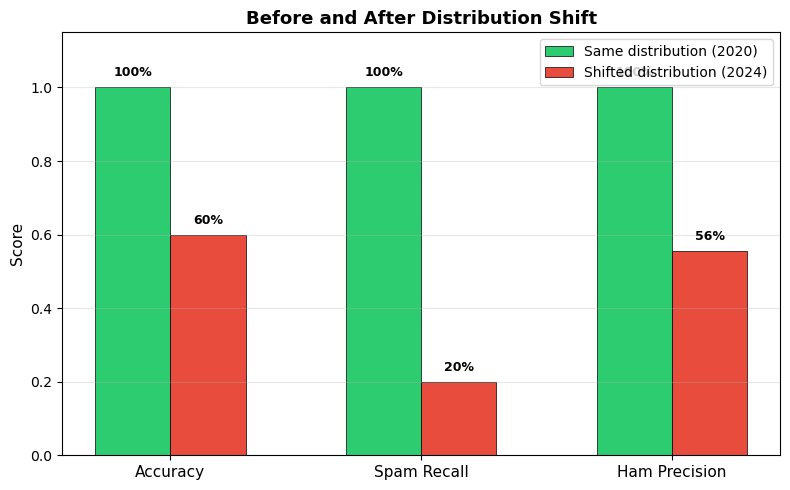

Performance degrades silently. Without monitoring, you won't know.
This is why deployed models need continuous evaluation — not just initial testing.


In [6]:
if simulate_shift(classifier, TEST_SHIFTED) is None:
    print("\u26a0 Implement simulate_shift first!")
else:
    shifted_metrics = simulate_shift(classifier, TEST_SHIFTED)
    plot_shift_comparison(same_metrics, shifted_metrics)
    print("Performance degrades silently. Without monitoring, you won't know.")
    print("This is why deployed models need continuous evaluation \u2014 not just initial testing.")

### Analyse the shift

Look at the results above and answer:

1. Which metric degrades most: accuracy, spam recall, or ham precision? Why does that metric suffer more than the others?
2. What specific words or patterns does the 2024 spam use that the 2020-trained classifier has never seen?
3. How would you detect this degradation in a production system if you didn't have labelled 2024 data?

1. Spam recall degrades the most (100  to 20 percent) because the classifier doesnt recognize the new spam messages and auto labels them as ham. Accuracy and precision also see a decline but not to the extent of recall, this is because the classifier still classifies the valid messages as ham correctly. 
2. Package delivery failed, verify your address, account security update, remote position, and resume.
3. Monitoring unseen words and tracking them, observing user complaints, and looking for any substantial sudden changes in the spam ratio.

---

## C4.2: Model Card: Documenting What Your Model Can and Can't Do

A **Model Card** (Mitchell et al., 2018) is a standardised document that accompanies a trained model. Think of it as a **nutrition label for AI**: you wouldn't eat food without knowing what's in it, and you shouldn't deploy a model without knowing what it can and can't do.

A Model Card answers:
- What was the model trained on?
- What is it intended to do?
- How well does it perform, and for whom?
- What are its limitations and failure modes?
- What are the ethical risks?

### Choose your model

Pick **one** model you built this semester to document:
- **Option A:** Naive Bayes spam classifier (W7 / P7)
- **Option B:** Weighted-sum classifier (W8 / P8)
- **Option C:** CV pipeline with convolution (C3), if you completed C3

Fill in every section below with details **specific to your chosen model**. Generic answers (e.g., "Limitations: none") will not be accepted.

### Your Model Card

**Model chosen:** *Naive Bayes*

---

#### Section 1: Model Details

| Field | Your Answer |
|-------|-------------|
| Architecture (e.g., Naive Bayes, weighted-sum threshold, convolution pipeline) | Naive Bayes |
| Training data (size + description) |Curated dataset of 23 small text/email messages in 2020 |
| Training date | 2025|
| Key hyperparameters (e.g., alpha=1 for Laplace smoothing, threshold value, kernel size) | alpha=1|
| Feature representation (e.g., bag-of-words, pixel arrays, edge features) |bag-of-words |

---

#### Section 2: Intended Use

- **Designed for:** Filtering the 2020 messages into spam or legitimate texts
- **Intended users:** Email/SMS users
- **NOT intended for:** Post 2024 spam detection, longer emails/texts

---

#### Section 3: Performance

| Metric | Same Distribution | Shifted Distribution (if tested) |
|--------|-------------------|----------------------------------|
| Accuracy | 100%|60% |
| Recall (positive class) |100% | 20%|
| Precision (negative class) |100% | 56%|

**Known failure modes:** New spam methods (that dont contain the words trained on). Spammer can just add a few ham words to the spam message.

---

#### Section 4: Limitations *(most important section)*

Be specific and honest. List at least **four** limitations:

1. Outdated and limited small dataset
2. Words are independent (naive)
3. Non-english, emojis, spelling differences
4. Vulnerable to distribution shift as the language and tactics change

---

#### Section 5: Ethical Considerations

- **Who is harmed by false positives?** The user when an important message goes to spam
- **Who is harmed by false negatives?** The user when they interact with phishing links that the classifier deemed legitimate
- **Demographic analysis:** No. It is a problem because the vocabulary used differs among demographics (spam in one can be a ham word in another)

---

#### Section 6: Deployment Recommendation

**Recommendation:** Do not deploy

**Justification:** It fails under distribution shift with a 20% recall on modern data. It first needs to be trained on a larger, more modern dataset before considering deployment.

### Peer comparison: spot the problems

Below is a deliberately weak Model Card. Read it and identify **three specific problems**: what information is missing, misleading, or dangerously vague?

In [7]:
print(WEAK_MODEL_CARD)


MODEL CARD: Spam Classifier

1. MODEL DETAILS
   - It's a Naive Bayes classifier
   - Trained on some messages

2. INTENDED USE
   - Classifying messages

3. PERFORMANCE
   - Accuracy: 100%

4. LIMITATIONS
   - None

5. ETHICAL CONSIDERATIONS
   - N/A

6. DEPLOYMENT RECOMMENDATION
   - Ready to deploy



**Three problems with the weak Model Card:**

1. Some messages is very vague. This can be mean it was trained on the 2020 data and so is completely useless for 2024+ applications.
2. No limitations is simply a false statment. It gives the users of this classfifier false confidence and then they arent aware of the potential limitations. Naive Bayes does have several known limitations as mentioned prior.
3. No ethiccal considerations is a big oversight. Missclassifying messages has real-world financial and legal consequences especially with bad recalls and precisions when dealing with critical or urgent messages.

---

## C4.3: Carbon Estimation: How Much Does Training Cost the Planet?

Training large AI models consumes enormous energy. GPT-4's training energy is estimated at 50+ GWh (Epoch AI; OpenAI has not disclosed the exact figure). Even if this estimate is off by a factor of two, the order of magnitude is staggering: enough to power thousands of homes for a year.

The calculation is straightforward:

$$\text{CO}_2 \text{ (kg)} = \text{Energy (kWh)} \times \text{Carbon intensity (kg CO}_2\text{/kWh)}$$

And training energy depends on:

$$\text{Energy (kWh)} = \frac{\text{GPU power (W)} \times \text{Number of GPUs} \times \text{Hours}}{1000}$$

The challenge is not the arithmetic: it's understanding the **scale**. A single ChatGPT query uses roughly 0.3 Wh (Epoch AI, 2025): about five seconds of Netflix streaming. The environmental cost of AI is overwhelmingly about **training frontier models**, not about individual use.

### Implement the estimation functions

In [8]:
def estimate_training_energy(gpu_power_watts, num_gpus, hours):
    """Estimate total training energy in kWh.

    Args:
        gpu_power_watts: Power draw per GPU in watts.
        num_gpus: Number of GPUs used.
        hours: Training duration in hours.

    Returns:
        Total energy in kWh.
    """
    # --- YOUR CODE HERE ---
    return (gpu_power_watts * num_gpus * hours) / 1000
    # --- END YOUR CODE ---


def estimate_carbon(energy_kwh, carbon_intensity):
    """Estimate CO2 emissions from energy consumption.

    Args:
        energy_kwh: Energy consumed in kWh.
        carbon_intensity: Grid carbon intensity in kg CO2 per kWh.

    Returns:
        Total CO2 emissions in kg.
    """
    # --- YOUR CODE HERE ---
    return energy_kwh * carbon_intensity
    # --- END YOUR CODE ---

In [9]:
# Test the functions
if estimate_training_energy(300, 10, 100) is None:
    print("\u26a0 estimate_training_energy returned None \u2014 implement it first!")
elif estimate_carbon(1000, 0.5) is None:
    print("\u26a0 estimate_carbon returned None \u2014 implement it first!")
else:
    # Quick sanity check
    test_energy = estimate_training_energy(300, 10, 100)
    print(f"10 GPUs \u00d7 300W \u00d7 100h = {test_energy:.0f} kWh")
    print(f"Check: should be 300: {'\u2713' if abs(test_energy - 300) < 0.1 else '\u2717'}")
    print()
    test_co2 = estimate_carbon(1000, 0.5)
    print(f"1000 kWh \u00d7 0.5 kg/kWh = {test_co2:.0f} kg CO\u2082")
    print(f"Check: should be 500: {'\u2713' if abs(test_co2 - 500) < 0.1 else '\u2717'}")

10 GPUs × 300W × 100h = 300 kWh
Check: should be 300: ✓

1000 kWh × 0.5 kg/kWh = 500 kg CO₂
Check: should be 500: ✓


### GPT-4's carbon footprint

Use the constants from `CARBON_CONSTANTS` and `COMPARISON_VALUES` to compute GPT-4's training emissions and express them in everyday terms.

In [10]:
if estimate_carbon(1000, 0.5) is None:
    print("\u26a0 Implement estimate_carbon first!")
else:
    # GPT-4 training
    gpt4_energy_kwh = CARBON_CONSTANTS['gpt4_energy_gwh'] * 1_000_000
    gpt4_co2_kg = estimate_carbon(gpt4_energy_kwh, CARBON_CONSTANTS['us_carbon_intensity'])
    gpt4_co2_tonnes = gpt4_co2_kg / 1000

    print("=== GPT-4 Training Carbon Footprint ===")
    print(f"Training energy:     {CARBON_CONSTANTS['gpt4_energy_gwh']} GWh = {gpt4_energy_kwh:,.0f} kWh")
    print(f"Grid intensity:      {CARBON_CONSTANTS['us_carbon_intensity']} kg CO\u2082/kWh (US average)")
    print(f"Training emissions:  {gpt4_co2_tonnes:,.0f} tonnes CO\u2082")
    print()
    print("Equivalent to:")
    print(f"  {gpt4_co2_kg / COMPARISON_VALUES['car_annual_co2_kg']:,.0f} cars driven for one year")
    print(f"  {gpt4_co2_kg / COMPARISON_VALUES['flight_syd_lon_co2_kg']:,.0f} Sydney\u2013London flights")
    print(f"  {gpt4_co2_kg / COMPARISON_VALUES['household_annual_co2_kg']:,.0f} US households' annual electricity")
    print()
    print("And this is JUST training. Inference adds more.")

=== GPT-4 Training Carbon Footprint ===
Training energy:     50 GWh = 50,000,000 kWh
Grid intensity:      0.39 kg CO₂/kWh (US average)
Training emissions:  19,500 tonnes CO₂

Equivalent to:
  4,239 cars driven for one year
  7,800 Sydney–London flights
  2,600 US households' annual electricity

And this is JUST training. Inference adds more.


### Your semester's carbon footprint

Now compute the carbon footprint of all FIT1061 computation across the whole semester: both lab work on your laptop and any AI chatbot queries you make.

In [11]:
if estimate_carbon(1000, 0.5) is None:
    print("\u26a0 Implement estimate_carbon first!")
else:
    c = CARBON_CONSTANTS

    # --- Lab computation (laptops) ---
    lab_kwh = (c['semester_labs'] * c['lab_hours'] *
               c['laptop_power_watts'] * c['semester_students']) / 1000
    lab_co2_kg = estimate_carbon(lab_kwh, c['au_carbon_intensity'])

    # --- AI inference (chatbot queries) ---
    total_queries = (c['semester_students'] * c['student_queries_per_week']
                     * c['semester_weeks'])
    inference_kwh = (total_queries * c['query_energy_wh']) / 1000
    # Inference runs on US data centres (mostly)
    inference_co2_kg = estimate_carbon(inference_kwh, c['us_carbon_intensity'])

    # --- Combined ---
    semester_kwh = lab_kwh + inference_kwh
    semester_co2_kg = lab_co2_kg + inference_co2_kg

    print("=== Our Semester's Carbon Footprint ===")
    print()
    print("Lab computation (laptops):")
    print(f"  {c['semester_labs']} labs \u00d7 {c['lab_hours']}h \u00d7 "
          f"{c['laptop_power_watts']}W \u00d7 {c['semester_students']} students")
    print(f"  Energy: {lab_kwh:,.0f} kWh  |  CO\u2082: {lab_co2_kg:,.1f} kg "
          f"(AU grid: {c['au_carbon_intensity']} kg/kWh)")
    print()
    print("AI inference (chatbot queries):")
    print(f"  {c['semester_students']} students \u00d7 {c['student_queries_per_week']} queries/week"
          f" \u00d7 {c['semester_weeks']} weeks = {total_queries:,} queries")
    print(f"  At {c['query_energy_wh']} Wh/query (Epoch AI, 2025)")
    print(f"  Energy: {inference_kwh:,.1f} kWh  |  CO\u2082: {inference_co2_kg:,.1f} kg "
          f"(US grid: {c['us_carbon_intensity']} kg/kWh)")
    print()
    print(f"Semester total:  {semester_kwh:,.0f} kWh  |  {semester_co2_kg:,.0f} kg CO\u2082 "
          f"({semester_co2_kg/1000:.2f} tonnes)")
    print(f"Per student:     {semester_co2_kg / c['semester_students']:.2f} kg CO\u2082")
    print(f"  (About {semester_co2_kg / c['semester_students'] / COMPARISON_VALUES['flight_syd_lon_co2_kg'] * 100:.2f}% "
          f"of a Sydney\u2013London flight)")
    print()
    print(f"Compare to GPT-4: {gpt4_co2_tonnes:,.0f} tonnes")
    print(f"Our semester:     {semester_co2_kg/1000:.2f} tonnes")
    print(f"Ratio:            GPT-4 is {gpt4_co2_kg / max(semester_co2_kg, 0.01):,.0f}\u00d7 our entire semester")
    print()
    print("Even including every chatbot query, our semester is trivial.")
    print("The environmental question is about training-time scale, not individual use.")

=== Our Semester's Carbon Footprint ===

Lab computation (laptops):
  12 labs × 2h × 30W × 200 students
  Energy: 144 kWh  |  CO₂: 95.0 kg (AU grid: 0.66 kg/kWh)

AI inference (chatbot queries):
  200 students × 50 queries/week × 12 weeks = 120,000 queries
  At 0.3 Wh/query (Epoch AI, 2025)
  Energy: 36.0 kWh  |  CO₂: 14.0 kg (US grid: 0.39 kg/kWh)

Semester total:  180 kWh  |  109 kg CO₂ (0.11 tonnes)
Per student:     0.55 kg CO₂
  (About 0.02% of a Sydney–London flight)

Compare to GPT-4: 19,500 tonnes
Our semester:     0.11 tonnes
Ratio:            GPT-4 is 178,768× our entire semester

Even including every chatbot query, our semester is trivial.
The environmental question is about training-time scale, not individual use.


### Side-by-side comparison

| | GPT-4 Training | FIT1061 Semester (labs + inference) | Ratio |
|---|---|---|---|
| **Energy** | 50,000,000 kWh | 180 kWh | ~278,000× |
| **CO₂** | 19,500 tonnes | 0.11 tonnes (109 kg) | ~179,000× |
| **Per student** | N/A | 0.55 kg CO₂ | N/A |
| **Equivalent** | ~4,239 cars/year | 0.02% of a Sydney–London flight | N/A |

The environmental question is about **scale**, not individual use. Your semester's entire computation (laptops *and* every chatbot query) is a rounding error compared to one frontier model training run.

> **Note on the 50 GWh estimate:** OpenAI has not disclosed GPT-4's exact training cost. The 50 GWh figure is an order-of-magnitude estimate from Epoch AI. Even if the true number is half or double, the ratio remains overwhelming.

### Visualise the scaling trend

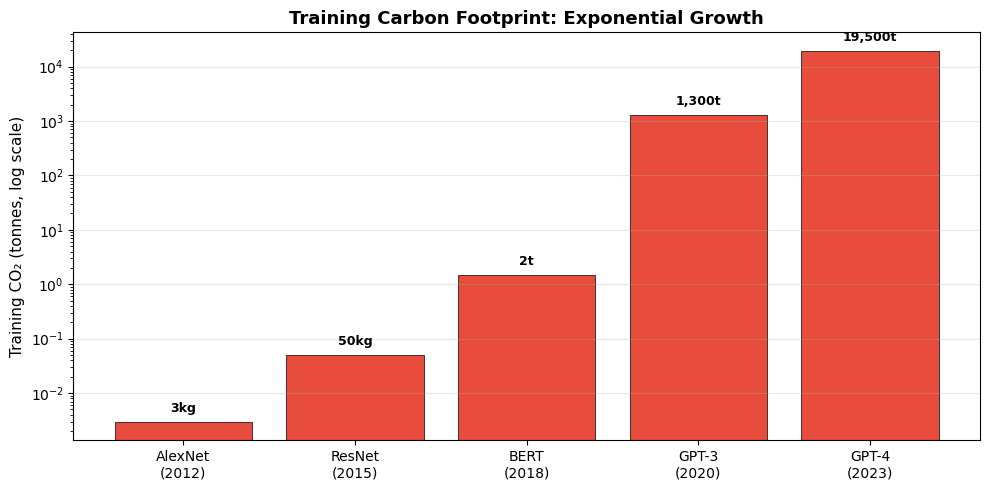

Training cost has grown ~6,000,000× in 11 years.
If this trend continues, the next generation of models
will consume the energy output of small countries.


In [12]:
plot_carbon_scaling()
print("Training cost has grown ~6,000,000\u00d7 in 11 years.")
print("If this trend continues, the next generation of models")
print("will consume the energy output of small countries.")

### Efficiency vs accuracy

The table below compares models you've built (Naive Bayes, Perceptron) against larger models you haven't. You don't need to know how BERT or GPT-4 work; just compare the numbers.

In [13]:
plot_efficiency_table()
print()
print("Naive Bayes: 95% accuracy at 0.001 kWh = extraordinary efficiency.")
print("GPT-4: 99% accuracy at 50,000 kWh = 4% improvement, 50 million\u00d7 cost.")
print()
print("The question isn't 'which is most accurate?'")
print("It's 'which is most accurate FOR THE COST?'")

                    Model  Accuracy       Compute     Acc/kWh
------------------------------------------------------------
         Naive Bayes (W7)       95%       0.001 kWh       950.0
          Perceptron (W8)       93%       0.002 kWh       465.0
      Logistic Regression       96%       0.010 kWh        96.0
     Small Neural Network       97%      10.000 kWh         0.1
          BERT fine-tuned       98%     100.000 kWh         0.0
         GPT-4 (few-shot)       99%   50000.000 kWh         0.0

Naive Bayes: 95% accuracy at 0.001 kWh = extraordinary efficiency.
GPT-4: 99% accuracy at 50,000 kWh = 4% improvement, 50 million× cost.

The question isn't 'which is most accurate?'
It's 'which is most accurate FOR THE COST?'


### Break-even: how many queries justify the training cost?

GPT-4's training consumed ~50 GWh. Each query uses ~0.3 Wh. How many queries does it take before the **amortised** training cost per query becomes negligible?

This is the **amortisation argument**: a large fixed cost (training) spread over a huge number of uses (inference) can make the per-use cost tiny: like building a highway vs driving on it.

In [14]:
if estimate_carbon(1000, 0.5) is None:
    print("\u26a0 Implement estimate_carbon first!")
else:
    c = CARBON_CONSTANTS

    # Training energy in kWh
    training_kwh = c['gpt4_energy_gwh'] * 1_000_000

    # Per-query energy in kWh
    query_kwh = c['query_energy_wh'] / 1000

    # Break-even: how many queries until amortised training = inference cost?
    break_even_queries = training_kwh / query_kwh

    # How long at current query volume?
    days_to_break_even = break_even_queries / c['gpt4_queries_per_day']

    print("=== Break-Even Analysis ===")
    print(f"Training energy:       {training_kwh:,.0f} kWh (one-time cost)")
    print(f"Per-query energy:      {query_kwh:.4f} kWh ({c['query_energy_wh']} Wh)")
    print(f"Break-even queries:    {break_even_queries:,.0f} ({break_even_queries/1e9:.0f} billion)")
    print(f"At ~{c['gpt4_queries_per_day']/1e9:.0f} billion queries/day: "
          f"{days_to_break_even:.0f} days (~{days_to_break_even/30:.0f} months)")
    print()

    # After 1 year: what fraction of per-query cost is training?
    queries_per_year = c['gpt4_queries_per_day'] * 365
    amortised_training_per_query = training_kwh / queries_per_year
    training_fraction = amortised_training_per_query / query_kwh

    print(f"After 1 year ({queries_per_year/1e9:.0f}B queries):")
    print(f"  Amortised training cost: {amortised_training_per_query:.6f} kWh/query")
    print(f"  Inference cost:          {query_kwh:.4f} kWh/query")
    print(f"  Training adds {training_fraction * 100:.0f}% to per-query energy")
    print()
    print("The training cost is enormous — but spread over billions of queries,")
    print("it becomes a fraction of the per-query inference cost.")
    print("This is the amortisation argument: fixed costs shrink with scale.")

=== Break-Even Analysis ===
Training energy:       50,000,000 kWh (one-time cost)
Per-query energy:      0.0003 kWh (0.3 Wh)
Break-even queries:    166,666,666,667 (167 billion)
At ~1 billion queries/day: 167 days (~6 months)

After 1 year (365B queries):
  Amortised training cost: 0.000137 kWh/query
  Inference cost:          0.0003 kWh/query
  Training adds 46% to per-query energy

The training cost is enormous — but spread over billions of queries,
it becomes a fraction of the per-query inference cost.
This is the amortisation argument: fixed costs shrink with scale.


### Your personal AI carbon footprint

How much carbon did YOUR chatbot use cost this semester? Estimate your own query count and compute it.

In [18]:
# --- YOUR PERSONAL AI FOOTPRINT ---
# Estimate: how many ChatGPT (or similar) queries did YOU make this semester?
# Be honest — check your chat history if you can.

my_queries = 700  # <-- REPLACE with your estimate

if my_queries == 0:
    print("\u26a0 Replace my_queries with your estimate!")
else:
    c = CARBON_CONSTANTS
    my_energy_kwh = (my_queries * c['query_energy_wh']) / 1000
    my_co2_kg = estimate_carbon(my_energy_kwh, c['us_carbon_intensity'])
    
    print(f"=== Your Personal AI Footprint ===")
    print(f"Queries this semester: {my_queries:,}")
    print(f"Energy: {my_energy_kwh:.3f} kWh")
    print(f"CO\u2082:    {my_co2_kg:.3f} kg")
    print()
    print("For comparison:")
    print(f"  = {my_co2_kg / COMPARISON_VALUES['flight_syd_lon_co2_kg'] * 100:.4f}% of a Sydney\u2013London flight")
    print(f"  = {my_energy_kwh / (50_000_000) * 100:.8f}% of GPT-4's training")
    print()
    print("Your individual AI use is environmentally negligible.")
    print("The question is not whether YOU should use less ChatGPT.")
    print("The question is who decides how many GPT-5s get trained.")


=== Your Personal AI Footprint ===
Queries this semester: 700
Energy: 0.210 kWh
CO₂:    0.082 kg

For comparison:
  = 0.0033% of a Sydney–London flight
  = 0.00000042% of GPT-4's training

Your individual AI use is environmentally negligible.
The question is not whether YOU should use less ChatGPT.
The question is who decides how many GPT-5s get trained.


### Scale vs individual use

You've now computed three things:
1. GPT-4's training footprint (massive)
2. The break-even point (training cost amortised over billions of queries)
3. Your personal AI footprint (negligible)

Based on these calculations: is the environmental cost of AI a problem of **individual use** (each student using ChatGPT) or of **scale** (training frontier models)? Does the amortisation argument change your answer? Justify with specific numbers.

It is a scaling problem. My usage (even though relatively high) is only a tiny fraction of a KG of CO2 - negligible compared to the 19500T used to train GPT4. However, in the case of a model serving billions of queries per day, the cost of training the model becomes very large but can be spread out, making only a small contribution to the cost of inference per query. The actual environmental problem isn't that a chatbot won't ask a few questions of a student, but when the use of a new frontier model makes sense given the amount of carbon we're paying up front.

---

## The Deployment Decision Framework

Before deploying any model, answer five questions:

In [19]:
print("=== Deployment Decision Framework ===")
print()
print("Before deploying any model, answer:")
print()
print("  1. PERFORMANCE")
print("     - What is the accuracy on held-out test data?")
print("     - What is the accuracy for each demographic group?")
print("     - What happens under distribution shift?")
print()
print("  2. MONITORING")
print("     - How will you detect performance degradation?")
print("     - What metrics will you track in production?")
print("     - How often will you retrain?")
print()
print("  3. FAILURE MODES")
print("     - What's the worst-case false positive? False negative?")
print("     - Who is harmed by each type of error?")
print("     - Is there a human in the loop for high-stakes decisions?")
print()
print("  4. SUSTAINABILITY")
print("     - What is the training and inference energy cost?")
print("     - Could a simpler model achieve acceptable performance?")
print("     - Is the environmental cost proportional to the benefit?")
print()
print("  5. THE PETROV QUESTION")
print("     - If the system is confidently wrong, can a human override it?")
print("     - Will that human have the information and authority to do so?")
print("     - Or will they be watching a video on their phone?")

=== Deployment Decision Framework ===

Before deploying any model, answer:

  1. PERFORMANCE
     - What is the accuracy on held-out test data?
     - What is the accuracy for each demographic group?
     - What happens under distribution shift?

  2. MONITORING
     - How will you detect performance degradation?
     - What metrics will you track in production?
     - How often will you retrain?

  3. FAILURE MODES
     - What's the worst-case false positive? False negative?
     - Who is harmed by each type of error?
     - Is there a human in the loop for high-stakes decisions?

  4. SUSTAINABILITY
     - What is the training and inference energy cost?
     - Could a simpler model achieve acceptable performance?
     - Is the environmental cost proportional to the benefit?

  5. THE PETROV QUESTION
     - If the system is confidently wrong, can a human override it?
     - Will that human have the information and authority to do so?
     - Or will they be watching a video on their ph

> **The Stanislav Petrov story:** On September 26, 1983, Soviet officer Stanislav Petrov received an alert: US nuclear missiles were inbound. The automated detection system showed high confidence. Protocol required him to launch a retaliatory strike. Petrov didn't launch. He judged the system was wrong: a false alarm from sunlight reflecting off clouds. He was right. His decision to **distrust the automated system** prevented nuclear war.
>
> Every deployed AI system will eventually produce a confident, wrong answer. The question is: will anyone be empowered to override it?

---

## Check Your Understanding

In [20]:
from jupyterquiz import display_quiz

c5_quiz = [
    {
        "question": "A spam classifier trained on 2020 data is deployed in 2024 without retraining. Which metric is MOST likely to degrade?",
        "type": "multiple_choice",
        "answers": [
            {"answer": "Spam recall \u2014 new spam tactics use words the classifier has never seen, so it misses them.",
             "correct": True,
             "feedback": "Correct! Distribution shift in spam means new spam evades the old model. The classifier still recognises ham (those patterns haven't changed much), but fails to catch new-style spam \u2014 so spam recall drops while ham precision stays high."},
            {"answer": "Ham precision \u2014 the classifier will incorrectly flag more legitimate messages as spam.",
             "correct": False,
             "feedback": "Ham patterns (meeting reminders, lunch plans) haven't changed much from 2020 to 2024. The model still recognises ham correctly. The problem is that new spam LOOKS like ham to the old model."},
            {"answer": "Both degrade equally \u2014 distribution shift affects all metrics the same way.",
             "correct": False,
             "feedback": "Distribution shift affects different metrics differently depending on WHAT shifted. In this case, spam tactics changed but ham patterns didn't, so spam recall degrades more than ham precision."},
            {"answer": "Neither \u2014 Naive Bayes is robust to distribution shift because of Laplace smoothing.",
             "correct": False,
             "feedback": "Laplace smoothing handles unseen words but doesn't prevent distribution shift. If all the spam signal-words ('free', 'prize') are absent from new spam, the classifier has no signal to work with."}
        ]
    },
    {
        "question": "Which section of a Model Card is most important for preventing harm?",
        "type": "multiple_choice",
        "answers": [
            {"answer": "Section 4 (Limitations) \u2014 it documents what the model CANNOT do, preventing misuse.",
             "correct": True,
             "feedback": "Correct! The Limitations section is the most important for preventing harm. Without it, users may deploy the model on data or tasks it was never designed for. Gender Shades happened because commercial models were deployed without documenting demographic performance gaps."},
            {"answer": "Section 3 (Performance) \u2014 high accuracy means the model is safe to deploy.",
             "correct": False,
             "feedback": "High overall accuracy can mask failures on specific groups or scenarios. The classifier in C4.1 had 100% accuracy on same-distribution data but only 60% on shifted data. A single accuracy number is misleading without context."},
            {"answer": "Section 1 (Model Details) \u2014 knowing the architecture prevents all misuse.",
             "correct": False,
             "feedback": "Model Details are important for reproducibility, but knowing the architecture doesn't tell you WHERE the model fails. A user could read 'Naive Bayes' and still deploy it on data it was never trained on."},
            {"answer": "Section 2 (Intended Use) \u2014 if users follow the intended use, no harm can occur.",
             "correct": False,
             "feedback": "Intended Use helps, but even within the intended use, a model can fail (e.g., distribution shift within the same task). Limitations documents failure modes that exist even when the model is used as designed."}
        ]
    },
    {
        "question": "Your Naive Bayes spam filter achieves 95% accuracy and costs 0.001 kWh to train. A large language model achieves 99% accuracy on the same task but costs 50,000 kWh. Which is the more responsible choice for a university email system?",
        "type": "multiple_choice",
        "answers": [
            {"answer": "Naive Bayes \u2014 the 4% accuracy gap does not justify a 50-million-fold increase in energy cost for a low-stakes application.",
             "correct": True,
             "feedback": "Correct! Green AI argues that efficiency should be a reported metric alongside accuracy. For spam filtering (low stakes, high volume), a 50-million-fold increase in compute for 4% accuracy is disproportionate. The responsible choice considers accuracy PER UNIT OF COST."},
            {"answer": "The LLM \u2014 4% more accuracy means fewer spam messages, which is always worth it.",
             "correct": False,
             "feedback": "'Always worth it' ignores the environmental cost. 4% improvement means roughly 4 fewer spam messages per 100. Is that worth the energy equivalent of thousands of households? Context matters \u2014 for spam filtering, the answer is almost certainly no."},
            {"answer": "It depends entirely on the budget \u2014 if the university can afford the LLM, there's no reason not to use it.",
             "correct": False,
             "feedback": "Affordability is one factor, but environmental cost exists regardless of who pays for it. Green AI asks us to consider efficiency as a first-class metric, not just accuracy and financial cost."},
            {"answer": "Neither \u2014 you should always build your own model from scratch for maximum control.",
             "correct": False,
             "feedback": "Building from scratch isn't inherently better. The question is about choosing the right tool for the job, considering both performance and environmental cost."}
        ]
    }
]

display_quiz(c5_quiz, shuffle_answers=True)

<IPython.core.display.Javascript object>

---

## Reflection: Should You Deploy It?

Write a reflection (300–500 words) engaging with this prompt:

> *"You've built a model that works in the notebook. Should you deploy it?"*

Your reflection should engage with the **deployment decision framework** (the five questions above):
- **Performance:** What happens under distribution shift?
- **Monitoring:** How would you detect degradation in production?
- **Failure modes:** Who is harmed by each type of error?
- **Sustainability:** Is the compute proportional to the benefit?
- **The Petrov question:** If the system is confidently wrong, can a human override it?

Reference at least **two** specific concepts from this task (distribution shift, model cards, carbon estimation) and connect to at least **one** earlier week's content (fairness from W9/C2, evaluation from W7, or a limitation from any earlier task).

> **Reading:** Margaret Mitchell et al., "Model Cards for Model Reporting" (2018). Roy Schwartz et al., "Green AI" (2020). Brian Christian, *The Alignment Problem*, Chapters 10–13.

Creating a model that performs well in a jupyter notebook is just part of the story - there's much more to consider when it comes to the risks, maintenance and impact of rolling the model out in the real world. The Naive Bayes spam classifier illustrates that with the same model, accuracy of 100% may be achieved on the test set, but fall to 60% when deployed in the wild. The world evolves and if the model does not evolve with it, then it becomes a handicap.

If I had to deploy a model I would have it to be actively monitored. If the data are not labeled in production, I would have to monitor the proxy metrics such as the overall number of positive predictions and/or when user error reports increase, to determine when retraining is needed. Also would have to think through what would fail. Depending on the domain, a false positive could simply be an inconvenience, while a false negative could have serious consequences. As we saw with the Week 9 study of Gender Shades, high overall accuracy often results in high rates of failure for certain minority groups. Otherwise, deployment may quickly amplify the biases in the model if it is not audited for fairness.

In addition, the deployment needs to address the Petrov question: When the system makes a very high-confidence call that is wrong, is there someone in the loop with the authority and context to overrule the system? With no human interaction in high stakes, the potential for harm is greatly increased. Last but not least, sustainability is a factor that shouldn't be overlooked. If a simple Perceptron or Naive Bayes model solves 95% of a problem for a fraction of a kilowatt-hour, spending 50 GWh to train a massive model for just a 4% improvement is hard to justify. It's not whether the code is deployed, it’s about the system being safe, equitable and proportional to the cost throughout its life cycle.

---

## Results Table

| Metric | Same Distribution | Shifted Distribution |
|--------|-------------------|---------------------|
| Accuracy |100% |60% |
| Spam Recall |100% |20% |
| Ham Precision |100% |56% |

| Carbon Estimation | Value |
|-------------------|-------|
| GPT-4 training emissions (tonnes CO₂) |19500 |
| Equivalent cars per year |4239 |
| Equivalent Sydney–London flights |7800 |
| Semester total emissions (kg CO₂), labs + inference |109 |
| Per-student emissions (kg CO₂) |0.55 |
| GPT-4 / semester ratio | 178768:1|
| Break-even queries (billions) |167 |
| Break-even time (days) |167 at 1b per day |
| Your personal queries | 700|
| Your personal CO₂ (kg) |0.082 |

---

## Submission Checklist

- [ ] **C4.1:** Prediction written (before running code)
- [ ] **C4.1:** `simulate_shift` function implemented and tested
- [ ] **C4.1:** Metric comparison table filled in
- [ ] **C4.1:** Degradation visualisation generated
- [ ] **C4.1:** Analysis of which metric degrades most and why
- [ ] **C4.2:** Model Card completed (all six sections, specific to your model)
- [ ] **C4.2:** Three problems identified in the weak Model Card
- [ ] **C4.3:** `estimate_carbon` and `estimate_training_energy` implemented
- [ ] **C4.3:** GPT-4 footprint computed with everyday comparisons
- [ ] **C4.3:** Semester footprint computed and compared to GPT-4
- [ ] **C4.3:** Break-even calculation completed
- [ ] **C4.3:** Personal AI footprint estimated
- [ ] **C4.3:** Scale vs individual use analysis written (with amortisation)
- [ ] Reflection on deployment readiness (300–500 words)
- [ ] Results table filled in
- [ ] Quiz completed
- [ ] All files uploaded to OnTrack

---

> **AI use policy (Credit level):**
> You may use AI to explain concepts or debug errors. Do not use AI to generate your Model Card, reflection, or written analysis. These must reflect your own thinking about your own model. Cite all AI use.

---

*FIT1061 Credit Task 4: Deployment & Model Cards*